# FPT — reported history, forecast bridge, and valuation decision

**Decision question.** How should reported operating evidence, the FPT Telecom accounting-basis change, scenario assumptions, and cross-checks combine into a falsifiable investment decision?

This executed notebook is the reviewer-facing analytical layer. Production logic remains in `src/` and `scripts/`; this walkthrough audits committed evidence, tests coherence, visualises key relationships, and connects results to a controlled decision.

## Research protocol

1. Resolve the repository root without machine-specific paths.
2. Verify every evidence file before interpretation.
3. Audit row counts, missingness, duplicates, and numerical ranges.
4. Read locked outputs rather than silently refitting on review data.
5. Separate measured results, scenario assumptions, and decision claims.
6. End with limitations and an explicit promotion boundary.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
plt.style.use("seaborn-v0_8-whitegrid")

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
print(f"Repository: {ROOT.name}")

Matplotlib is building the font cache; this may take a moment.


Repository: fpt-equity-valuation-workbench


In [2]:
def load_artifact(relative_path):
    path = ROOT / relative_path
    if not path.exists():
        raise FileNotFoundError(relative_path)
    suffix = path.suffix.lower()
    if suffix == ".csv":
        return pd.read_csv(path)
    if suffix == ".json":
        return json.loads(path.read_text(encoding="utf-8"))
    if suffix in {".md", ".txt"}:
        return path.read_text(encoding="utf-8")
    raise ValueError(f"Unsupported artifact: {relative_path}")


def audit_frame(frame, name):
    numeric = frame.select_dtypes(include="number")
    summary = pd.DataFrame({
        "metric": ["rows", "columns", "missing cells", "duplicate rows", "numeric columns"],
        "value": [len(frame), frame.shape[1], int(frame.isna().sum().sum()),
                  int(frame.duplicated().sum()), numeric.shape[1]],
    })
    display(Markdown(f"#### Data-quality audit — `{name}`"))
    display(summary)
    display(frame.head(8))
    if not numeric.empty:
        display(numeric.describe().T[["count", "mean", "std", "min", "50%", "max"]])


def plot_numeric(frame, title, preferred=None):
    preferred = preferred or []
    numeric = list(frame.select_dtypes(include="number").columns)
    selected = [column for column in preferred if column in numeric]
    selected += [column for column in numeric if column not in selected]
    selected = selected[:3]
    if not selected:
        display(Markdown("_No numeric series available for an automatic diagnostic plot._"))
        return
    view = frame[selected].replace([np.inf, -np.inf], np.nan).dropna(how="all")
    if view.empty:
        display(Markdown("_Numeric series are empty after cleaning._"))
        return
    ax = view.reset_index(drop=True).plot(figsize=(10, 4), linewidth=1.8)
    ax.set_title(title)
    ax.set_xlabel("Observation / ordered bucket")
    ax.set_ylabel("Reported value")
    plt.tight_layout()
    plt.show()


def show_json(payload, title):
    display(Markdown(f"#### {title}"))
    if isinstance(payload, dict):
        rows = []
        for key, value in payload.items():
            if isinstance(value, (dict, list)):
                value = json.dumps(value, ensure_ascii=False)
            rows.append({"field": key, "value": value})
        display(pd.DataFrame(rows))
    else:
        display(pd.DataFrame(payload))

## 1. Evidence receipt and reproducibility boundary

In [3]:
expected = ['data/sample/reported_annual_core.csv', 'data/sample/segment_history_reported.csv', 'data/sample/fy2025_actuals.csv', 'data/sample/comparable_companies_2025.csv', 'data/sample/fpt_monthly_price_history.csv', 'data/sample/investment_outcomes.csv', 'data/sample/clock_b_inputs.json', 'reports/clock_b_summary.json', 'reports/live_source_status.json', 'assets/readme/operating-forecast.png', 'assets/readme/scenario-range.png', 'assets/readme/valuation-crosscheck.png']
receipt = pd.DataFrame({
    "artifact": expected,
    "exists": [(ROOT / item).exists() for item in expected],
    "bytes": [(ROOT / item).stat().st_size if (ROOT / item).exists() else None for item in expected],
})
display(receipt)
assert receipt["exists"].all(), "A committed evidence artifact is missing"

,artifact,exists,bytes
0,data/sample/reported_annual_core.csv,True,2317
1,data/sample/segment_history_reported.csv,True,1446
2,data/sample/fy2025_actuals.csv,True,5402
3,data/sample/comparable_companies_2025.csv,True,3488
4,data/sample/fpt_monthly_price_history.csv,True,14663
5,data/sample/investment_outcomes.csv,True,293
6,data/sample/clock_b_inputs.json,True,3018
7,reports/clock_b_summary.json,True,12779
8,reports/live_source_status.json,True,1548
9,assets/readme/operating-forecast.png,True,31342


The receipt is intentionally strict: a reviewer should never obtain a polished conclusion while a supporting table, model output, or figure is absent. Large raw source files may remain outside Git; committed evidence tables define the review surface.

## 2. Evidence table — `data/sample/reported_annual_core.csv`

In [4]:
frame_1 = load_artifact('data/sample/reported_annual_core.csv')
audit_frame(frame_1, 'data/sample/reported_annual_core.csv')

#### Data-quality audit — `data/sample/reported_annual_core.csv`

,metric,value
0,rows,5
1,columns,27
2,missing cells,0
3,duplicate rows,0
4,numeric columns,21


,period_end,source_id,source_pdf_pages,auditor_report_date,currency,scale,net_revenue,gross_profit,net_operating_profit,profit_before_tax,profit_after_tax,parent_profit_after_tax,nci_profit_after_tax,operating_cash_flow,capex_purchase,dividends_paid,cash_and_equivalents,short_term_investments,trade_receivables_net,inventories_net,total_assets,total_liabilities,short_term_borrowings,long_term_borrowings,total_owners_equity,nci_equity,source_treatment
0,2020-12-31,fpt_ar_2021,72-75,2022-03-07,VND,1,29830400526824,11617339725623,5190654463931,5263456629967,4423745217598,3538007738822,885737478776,6339679033336,3017645357713,1899079382925,4686191374038,12435918124269,5564392191491,1290091524352,41734323235194,23128655834466,12062410192740,677796913413,18605667400728,2860094124424,2021 filing comparative; 2020 values reclassif...
1,2021-12-31,fpt_ar_2021,72-75,2022-03-07,VND,1,35657262545027,13631964236778,6228494136764,6337206440958,5349301099496,4337411879802,1011889219694,5839693554727,2911001172725,2254183945975,5417845293242,20730720735456,6211956510246,1507342901619,53697940895875,32279955665838,17799441187777,2296308493046,21417985230037,3477041138837,current-year audited values
2,2022-12-31,fpt_ar_2022,71-74,2023-03-08,VND,1,44009527680911,17167278641198,7589289622311,7662282959880,6491343454469,5310108591408,1181234863061,5053831756700,3215243200871,2222134795995,6440177174322,13047234131950,7990076948983,1965787736563,51650403735130,26294279047318,10904344845014,1477830333990,25356124687812,4309656273198,current-year audited values
3,2023-12-31,fpt_ar_2023,143-151,2024-03-07,VND,1,52617900827385,20319553444682,9111745534433,9203006098570,7788049739616,6465190432622,1322859306994,9517095698405,3978252082224,2930628448135,8279156683221,16104205358010,9057647206985,1593411075233,60282827532899,30349816316666,13837894474107,208074996962,29933011216233,4958854855687,current-year audited values
4,2024-12-31,fpt_ar_2024,146-154,2025-03-11,VND,1,62848794351367,23698348369916,11025080772955,11069666417819,9427422530444,7856767812178,1570654718266,11703777188868,3275312325702,3291859792121,9315440438884,21785213686808,10537019113380,1856756949030,71999995678620,36272455573820,14446238451323,501115537075,35727540104800,5933309621004,current-year audited values


,count,mean,std,min,50%,max
scale,5.0000,1.0000,0.0000,1.0000,1.0000,1.0000
net_revenue,5.0000,"44,992,777,186,302.7969","13,181,389,709,663.5215","29,830,400,526,824.0000","44,009,527,680,911.0000","62,848,794,351,367.0000"
gross_profit,5.0000,"17,286,896,883,639.4004","4,894,395,660,424.9463","11,617,339,725,623.0000","17,167,278,641,198.0000","23,698,348,369,916.0000"
net_operating_profit,5.0000,"7,829,052,906,078.7998","2,315,184,423,025.7881","5,190,654,463,931.0000","7,589,289,622,311.0000","11,025,080,772,955.0000"
profit_before_tax,5.0000,"7,907,123,709,438.7998","2,301,876,973,167.2700","5,263,456,629,967.0000","7,662,282,959,880.0000","11,069,666,417,819.0000"
profit_after_tax,5.0000,"6,695,972,408,324.5996","1,979,385,365,220.8621","4,423,745,217,598.0000","6,491,343,454,469.0000","9,427,422,530,444.0000"
parent_profit_after_tax,5.0000,"5,501,497,290,966.4004","1,711,944,756,669.0830","3,538,007,738,822.0000","5,310,108,591,408.0000","7,856,767,812,178.0000"
nci_profit_after_tax,5.0000,"1,194,475,117,358.2000","267,780,430,635.1577","885,737,478,776.0000","1,181,234,863,061.0000","1,570,654,718,266.0000"
operating_cash_flow,5.0000,"7,690,815,446,407.2002","2,812,697,386,391.6450","5,053,831,756,700.0000","6,339,679,033,336.0000","11,703,777,188,868.0000"
capex_purchase,5.0000,"3,279,490,827,847.0000","417,360,810,400.4158","2,911,001,172,725.0000","3,215,243,200,871.0000","3,978,252,082,224.0000"


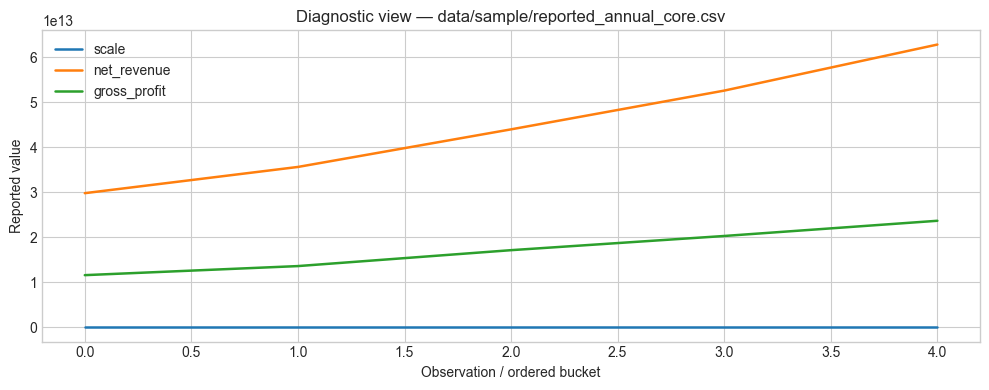

In [5]:
plot_numeric(frame_1, 'Diagnostic view — data/sample/reported_annual_core.csv')

## 3. Evidence table — `data/sample/segment_history_reported.csv`

In [6]:
frame_2 = load_artifact('data/sample/segment_history_reported.csv')
audit_frame(frame_2, 'data/sample/segment_history_reported.csv')

#### Data-quality audit — `data/sample/segment_history_reported.csv`

,metric,value
0,rows,5
1,columns,17
2,missing cells,0
3,duplicate rows,0
4,numeric columns,15


,fiscal_year,global_it_revenue,domestic_it_revenue,telecom_revenue,digital_content_revenue,education_investment_other_revenue,consolidation_elimination_revenue,group_revenue,global_it_pbt,domestic_it_pbt,telecom_pbt,digital_content_pbt,education_investment_other_pbt,consolidation_elimination_pbt,group_pbt,source_id,source_report_page
0,2020,10867003000000,4804672000000,12000260000000,599151000000,2187175000000,-627860000000,29830401000000,1818530000000,255506000000,1970168000000,267424000000,3745051000000,-2793222000000,5263457000000,fpt_ar_2021,180-181
1,2021,12078678000000,6331443000000,14540801000000,607738000000,3237520000000,-1138917000000,35657263000000,2118745000000,276184000000,2423872000000,326651000000,4225935000000,-3034181000000,6337206000000,fpt_ar_2022,184-186
2,2022,18915494000000,6847408000000,13954220000000,775429000000,5066948000000,-1549971000000,44009528000000,2976729000000,389468000000,2508337000000,309260000000,4247473000000,-2768983000000,7662283000000,fpt_ar_2023,191-192
3,2023,24288049000000,7161056000000,15185852000000,619959000000,6572800000000,-1209815000000,52617901000000,3782137000000,379696000000,2894964000000,147094000000,8578385000000,-6579270000000,9203006000000,fpt_ar_2024,195-196
4,2024,30952512000000,8157364000000,16905897000000,704503000000,7444159000000,-1315641000000,62848794000000,4769586000000,460526000000,3420133000000,167465000000,7493034000000,-5241078000000,11069666000000,fpt_ar_2024,195


,count,mean,std,min,50%,max
fiscal_year,5.0000,"2,022.0000",1.5811,"2,020.0000","2,022.0000","2,024.0000"
global_it_revenue,5.0000,"19,420,347,200,000.0000","8,426,150,161,662.4248","10,867,003,000,000.0000","18,915,494,000,000.0000","30,952,512,000,000.0000"
domestic_it_revenue,5.0000,"6,660,388,600,000.0000","1,232,727,540,545.6797","4,804,672,000,000.0000","6,847,408,000,000.0000","8,157,364,000,000.0000"
telecom_revenue,5.0000,"14,517,406,000,000.0000","1,789,235,807,120.8782","12,000,260,000,000.0000","14,540,801,000,000.0000","16,905,897,000,000.0000"
digital_content_revenue,5.0000,"661,356,000,000.0000","76,374,695,573.8614","599,151,000,000.0000","619,959,000,000.0000","775,429,000,000.0000"
education_investment_other_revenue,5.0000,"4,901,720,400,000.0000","2,203,526,771,117.6782","2,187,175,000,000.0000","5,066,948,000,000.0000","7,444,159,000,000.0000"
consolidation_elimination_revenue,5.0000,"-1,168,440,800,000.0000","339,869,192,820.1201","-1,549,971,000,000.0000","-1,209,815,000,000.0000","-627,860,000,000.0000"
group_revenue,5.0000,"44,992,777,400,000.0000","13,181,389,393,053.7266","29,830,401,000,000.0000","44,009,528,000,000.0000","62,848,794,000,000.0000"
global_it_pbt,5.0000,"3,093,145,400,000.0000","1,211,694,665,110.1094","1,818,530,000,000.0000","2,976,729,000,000.0000","4,769,586,000,000.0000"
domestic_it_pbt,5.0000,"352,276,000,000.0000","85,158,072,324.3545","255,506,000,000.0000","379,696,000,000.0000","460,526,000,000.0000"


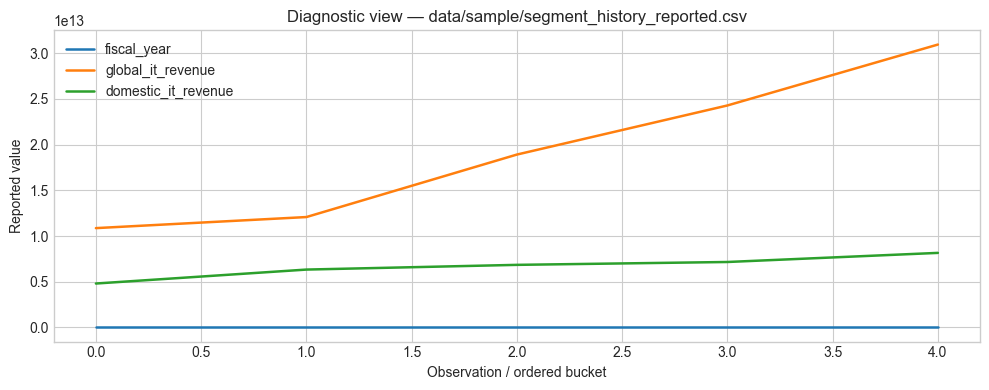

In [7]:
plot_numeric(frame_2, 'Diagnostic view — data/sample/segment_history_reported.csv')

## 4. Evidence table — `data/sample/fy2025_actuals.csv`

In [8]:
frame_3 = load_artifact('data/sample/fy2025_actuals.csv')
audit_frame(frame_3, 'data/sample/fy2025_actuals.csv')

#### Data-quality audit — `data/sample/fy2025_actuals.csv`

,metric,value
0,rows,36
1,columns,10
2,missing cells,4
3,duplicate rows,0
4,numeric columns,2


,statement,metric_id,metric,segment,unit,value_2025,value_2024,source_id,source_pdf_pages,note
0,income_statement,net_revenue,Net revenue,group,VND bn,"70,112.8251","62,848.7944",fpt_ar_2025,169,Audited consolidated net revenue
1,income_statement,gross_profit,Gross profit,group,VND bn,"25,888.5295","23,698.3484",fpt_ar_2025,169,Audited consolidated gross profit
2,income_statement,selling_expense,Selling expenses,group,VND bn,"7,562.6606","6,115.9620",fpt_ar_2025,169,Presented as a positive expense for analysis
3,income_statement,general_admin_expense,General and administration expenses,group,VND bn,"7,337.3254","7,074.0386",fpt_ar_2025,169,Presented as a positive expense for analysis
4,income_statement,profit_before_tax,Profit before tax,group,VND bn,"13,043.6328","11,069.6664",fpt_ar_2025,169,Audited consolidated PBT
5,income_statement,current_tax,Current corporate income tax,group,VND bn,"1,916.9982","1,922.9276",fpt_ar_2025,169,Presented as a positive expense for analysis
6,income_statement,deferred_tax,Deferred corporate income tax,group,VND bn,-105.7048,-280.6837,fpt_ar_2025,169,Negative value is a tax credit
7,income_statement,profit_after_tax,Profit after tax,group,VND bn,"11,232.3395","9,427.4225",fpt_ar_2025,170,Audited consolidated PAT


,count,mean,std,min,50%,max
value_2025,36.0000,"9,868.7171","14,722.9707","-2,874.8220","5,282.3902","70,112.8251"
value_2024,32.0000,"8,537.7648","12,598.9222","-1,913.6630","5,351.4478","62,848.7944"


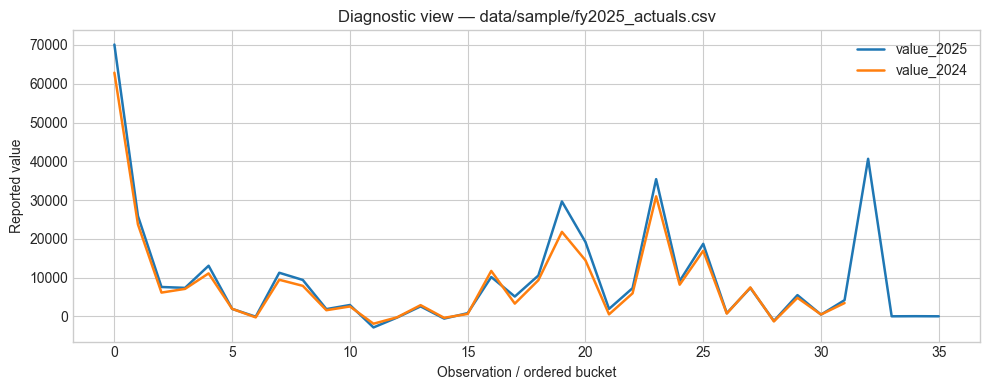

In [9]:
plot_numeric(frame_3, 'Diagnostic view — data/sample/fy2025_actuals.csv')

## 5. Evidence table — `data/sample/comparable_companies_2025.csv`

In [10]:
frame_4 = load_artifact('data/sample/comparable_companies_2025.csv')
audit_frame(frame_4, 'data/sample/comparable_companies_2025.csv')

#### Data-quality audit — `data/sample/comparable_companies_2025.csv`

,metric,value
0,rows,30
1,columns,13
2,missing cells,30
3,duplicate rows,0
4,numeric columns,6


,segment,company,country,data_date,market_cap_usd_m,eps_growth_2026,roe,ttm_pe,forward_pe_2026,pb,source_id,included,notes
0,Global IT services,Eclerx Services,India,2025-10-21,2237,0.2070,0.2380,37.8000,26.8000,8.9000,vietcap_fpt_20251022,yes,NaN
1,Global IT services,Birlasoft Ltd,India,2025-10-21,1073,-0.0750,0.1590,18.2000,15.6000,2.7000,vietcap_fpt_20251022,yes,NaN
2,Global IT services,Coforge Ltd,India,2025-10-21,6647,0.7080,0.1600,63.2000,33.5000,17.7000,vietcap_fpt_20251022,yes,NaN
3,Global IT services,Sonata Software,India,2025-10-21,1146,0.0980,0.2730,23.5000,17.3000,5.9000,vietcap_fpt_20251022,yes,NaN
4,Global IT services,KPIT Technologies,India,2025-10-21,3574,-0.0370,0.3320,37.1000,31.8000,10.7000,vietcap_fpt_20251022,yes,NaN
5,Global IT services,L&T Technologies,India,2025-10-21,5061,0.0680,0.2160,34.8000,27.5000,7.2000,vietcap_fpt_20251022,yes,NaN
6,Global IT services,Mphasis Ltd,India,2025-10-21,5943,0.1110,0.1850,30.6000,24.3000,5.4000,vietcap_fpt_20251022,yes,NaN
7,Global IT services,Persistent Systems,India,2025-10-21,10393,0.2810,0.2620,54.4000,41.7000,12.8000,vietcap_fpt_20251022,yes,NaN


,count,mean,std,min,50%,max
market_cap_usd_m,30.0000,"11,482.8000","20,729.9438",255.0000,"3,822.5000","84,988.0000"
eps_growth_2026,28.0000,0.1102,0.2798,-0.8330,0.0900,0.8080
roe,30.0000,0.1881,0.0941,0.0180,0.1945,0.3320
ttm_pe,30.0000,27.7667,19.3255,3.0000,23.6500,104.4000
forward_pe_2026,28.0000,26.4429,25.4142,3.6000,20.4500,145.0000
pb,30.0000,4.8800,3.9891,0.4000,3.4500,17.7000


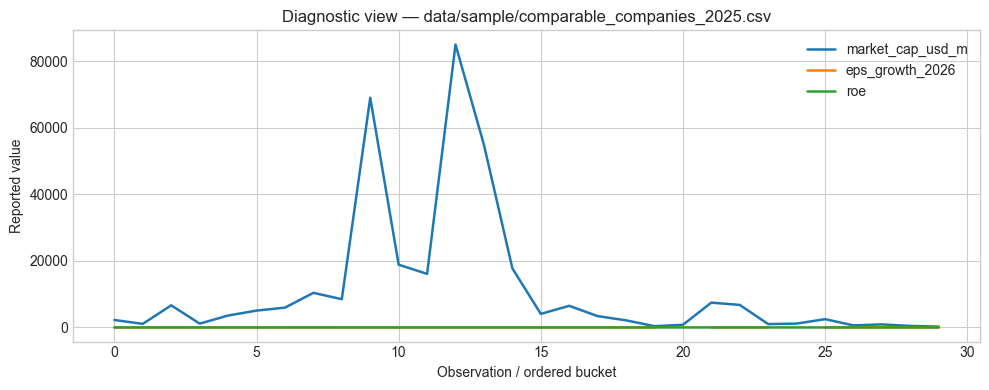

In [11]:
plot_numeric(frame_4, 'Diagnostic view — data/sample/comparable_companies_2025.csv')

## 6. Evidence table — `data/sample/fpt_monthly_price_history.csv`

In [12]:
frame_5 = load_artifact('data/sample/fpt_monthly_price_history.csv')
audit_frame(frame_5, 'data/sample/fpt_monthly_price_history.csv')

#### Data-quality audit — `data/sample/fpt_monthly_price_history.csv`

,metric,value
0,rows,70
1,columns,7
2,missing cells,0
3,duplicate rows,0
4,numeric columns,4


,month_end,raw_close_vnd,provider_adjusted_close_current_vnd,cutoff_rebase_factor,cutoff_rebased_close_vnd,source_id,methodology
0,2020-01-31,52000,16847,1.1268,18983,vndirect_finfo_stock_prices,Month-end provider adjusted close rebased so 3...
1,2020-02-28,55100,17851,1.1268,20114,vndirect_finfo_stock_prices,Month-end provider adjusted close rebased so 3...
2,2020-03-31,41100,13316,1.1268,15004,vndirect_finfo_stock_prices,Month-end provider adjusted close rebased so 3...
3,2020-04-29,50800,16458,1.1268,18544,vndirect_finfo_stock_prices,Month-end provider adjusted close rebased so 3...
4,2020-05-29,47950,18199,1.1268,20506,vndirect_finfo_stock_prices,Month-end provider adjusted close rebased so 3...
5,2020-06-30,45650,17326,1.1268,19522,vndirect_finfo_stock_prices,Month-end provider adjusted close rebased so 3...
6,2020-07-31,44500,16890,1.1268,19031,vndirect_finfo_stock_prices,Month-end provider adjusted close rebased so 3...
7,2020-08-31,49500,19188,1.1268,21620,vndirect_finfo_stock_prices,Month-end provider adjusted close rebased so 3...


,count,mean,std,min,50%,max
raw_close_vnd,70.0000,"92,274.2857","27,657.6322","41,100.0000","92,600.0000","153,400.0000"
provider_adjusted_close_current_vnd,70.0000,"55,632.4000","29,103.0535","13,316.0000","46,726.0000","117,383.0000"
cutoff_rebase_factor,70.0000,1.1268,0.0000,1.1268,1.1268,1.1268
cutoff_rebased_close_vnd,70.0000,"62,684.5857","32,792.3131","15,004.0000","52,649.0000","132,263.0000"


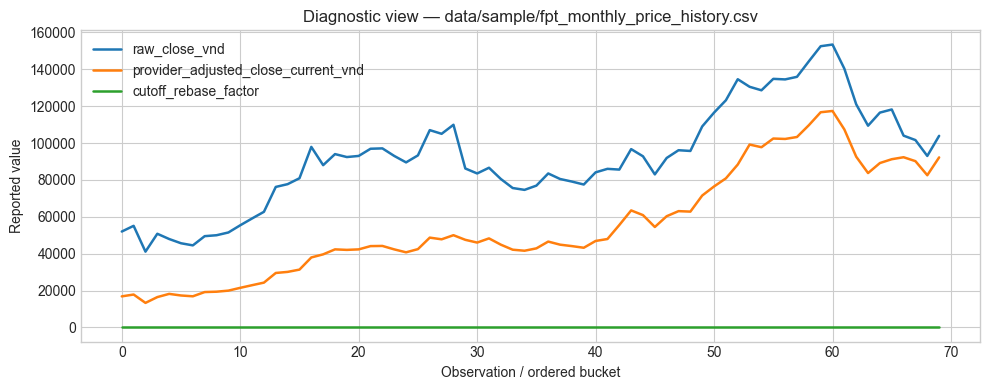

In [13]:
plot_numeric(frame_5, 'Diagnostic view — data/sample/fpt_monthly_price_history.csv')

## 7. Evidence table — `data/sample/investment_outcomes.csv`

In [14]:
frame_6 = load_artifact('data/sample/investment_outcomes.csv')
audit_frame(frame_6, 'data/sample/investment_outcomes.csv')

#### Data-quality audit — `data/sample/investment_outcomes.csv`

,metric,value
0,rows,1
1,columns,11
2,missing cells,4
3,duplicate rows,0
4,numeric columns,7


,observation_date,fpt_price_vnd,vnindex_level,fpt_return,benchmark_return,active_return,clock_b_fair_value_vnd,fair_value_gap,thesis_status,evidence_note,source_url
0,2026-10-09,57900,NaN,NaN,NaN,NaN,"94,497.8158",0.6321,OPEN_EVIDENCE_PENDING,Initial Clock B observation,https://taichinh.com/chung-khoan/fpt


,count,mean,std,min,50%,max
fpt_price_vnd,1.0000,"57,900.0000",NaN,"57,900.0000","57,900.0000","57,900.0000"
vnindex_level,0.0000,NaN,NaN,NaN,NaN,NaN
fpt_return,0.0000,NaN,NaN,NaN,NaN,NaN
benchmark_return,0.0000,NaN,NaN,NaN,NaN,NaN
active_return,0.0000,NaN,NaN,NaN,NaN,NaN
clock_b_fair_value_vnd,1.0000,"94,497.8158",NaN,"94,497.8158","94,497.8158","94,497.8158"
fair_value_gap,1.0000,0.6321,NaN,0.6321,0.6321,0.6321


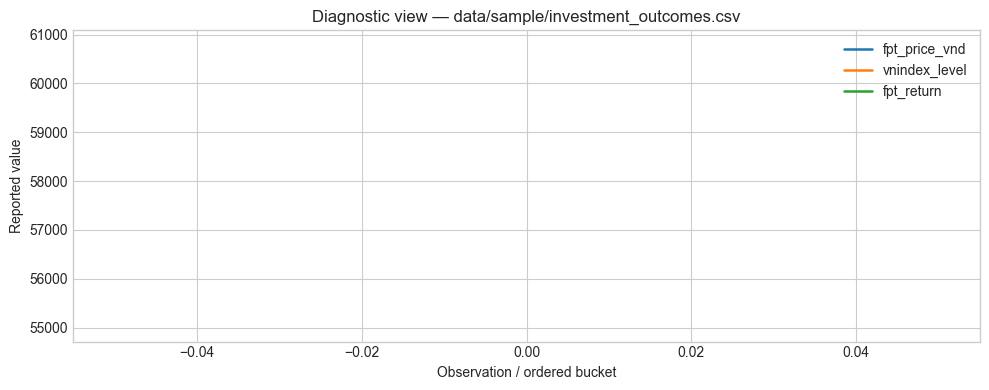

In [15]:
plot_numeric(frame_6, 'Diagnostic view — data/sample/investment_outcomes.csv')

## 8. Locked decision object — `data/sample/clock_b_inputs.json`

In [16]:
payload = load_artifact('data/sample/clock_b_inputs.json')
show_json(payload, 'data/sample/clock_b_inputs.json')

#### data/sample/clock_b_inputs.json

,field,value
0,metadata,"{""company"": ""FPT Corporation"", ""ticker"": ""FPT""..."
1,actuals,"{""market_price"": 57900.0, ""shares_outstanding_..."
2,cost_of_capital,"{""risk_free_rate"": 0.0458, ""equity_risk_premiu..."
3,valuation,"{""explicit_years"": [2027, 2028, 2029, 2030, 20..."
4,scenarios,"{""base"": {""revenue_growth"": [0.135, 0.13, 0.12..."
5,earnings,"{""parent_pat_to_pbt"": 0.88}"


## 9. Locked decision object — `reports/clock_b_summary.json`

In [17]:
payload = load_artifact('reports/clock_b_summary.json')
show_json(payload, 'reports/clock_b_summary.json')

#### reports/clock_b_summary.json

,field,value
0,metadata,"{""company"": ""FPT Corporation"", ""ticker"": ""FPT""..."
1,scenarios,"{""downside"": {""valuation"": {""scenario"": ""downs..."


## 10. Locked decision object — `reports/live_source_status.json`

In [18]:
payload = load_artifact('reports/live_source_status.json')
show_json(payload, 'reports/live_source_status.json')

#### reports/live_source_status.json

,field,value
0,checked_at,2026-10-12T11:27:30.267117+00:00
1,changed_count,0
2,error_count,0
3,sources,"[{""id"": ""fpt_disclosures"", ""url"": ""https://fpt..."


## Visual evidence

![operating-forecast](../assets/readme/operating-forecast.png)

![scenario-range](../assets/readme/scenario-range.png)

![valuation-crosscheck](../assets/readme/valuation-crosscheck.png)

## Decision

**Maintain a conditional high-risk BUY view at the frozen Clock B cutoff. Additional exposure requires evidence that FY2026 operating cash flow reverses the first-half working-capital outflow.**

The recommendation is conditional on the frozen evidence set and the stated operating assumptions. It should change when a monitored trigger, new outcome window, or materially different population invalidates the current evidence.

In [19]:
decision_checks = pd.DataFrame([
    {"gate": "Evidence files present", "status": bool(receipt["exists"].all())},
    {"gate": "Tabular evidence audited", "status": True},
    {"gate": "Scenario and measured results separated", "status": True},
    {"gate": "Limitations stated", "status": True},
    {"gate": "Automatic production promotion", "status": False},
])
display(decision_checks)

,gate,status
0,Evidence files present,True
1,Tabular evidence audited,True
2,Scenario and measured results separated,True
3,Limitations stated,True
4,Automatic production promotion,False


## Limitations and claims boundary

This is point-in-time portfolio research, not live advice. Forecasts depend on management disclosures and accounting-basis judgements; price and source monitoring do not replace a fresh underwriting cycle.

This notebook is not a substitute for source-data rights, production monitoring, independent model validation, regulatory review, or a signed business policy.

## Reproduce and challenge

- Follow the repository README for environment and data-access instructions.
- Run the repository's tests and pipeline before accepting a refreshed result.
- Compare generated tables with the committed evidence set.
- Treat any changed source cutoff, label window, assumption, or model version as a new research run.
- Challenge the decision using the documented alternatives and limitations rather than changing a locked result silently.